<a href="https://colab.research.google.com/github/MewtwoRBGY/git-starter-MewtwoRBGY/blob/main/Racca_DS_S03_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solo Assignment 03 — Regression on Pet Anxiety Dataset (25 ⭕️s)
_Course:_ Intro to Data Science · _Runtime:_ Python 3 · _Kernel:_ IPykernel

_Points guide:_ ⭕️ = 1 point · Total = 25 ⭕️

Joe Racca

## Overview


You will examine a synthetic dataset from a **vet clinic**. You will find models to predict the anxiety experience by pets visiting the clinic and then you will make recommendations based on what you learn from fitting those models.

**What you’ll practice in this notebook**

1. Fit and interpret **Linear and/or Polynomial Regression**
2. Evaluate the ML models you fit with **R²**, residuals, and visualization of actual vs predicted values
3. Evaluate fits and make recommendations based on your results.


## Task 1 — Load, Inspect & Summarize


- Load `vet_anxiety.csv` into a DataFrame `df`
- Show `.head()`, `.info()`, and basic `.describe()`; compute `.nunique()` for categoricals
- Create a quick correlation heatmap of numeric variables (use `seaborn.heatmap`)  


Downloading...
From: https://drive.google.com/uc?id=1Z6KAI-3rd7zmwcuOVu_lC9WXiMgYI9zM
To: /content/pets_vet_anxiety_dataset-1.csv
100%|██████████| 20.1k/20.1k [00:00<00:00, 20.0MB/s]


,Pet_ID,Visit_ID,Pet_Name,Species,Age_Years,Pet_Weight_kg,Health_Score,Visit_Length,Wait_Time,Owner_Calmness,Treats_Given,Invasive_Treatment,Anxiety
0,P0001,V000001,Nano,Dog,7,12.60,10.0,15,16,10.0,1,False,4.0
1,P0002,V000002,Leo,Dog,3,25.41,5.7,52,8,7.0,1,False,3.0
2,P0003,V000003,Rosie,Cat,7,4.92,5.9,60,26,5.0,0,True,10.0
3,P0004,V000004,Teddy,Cat,14,6.12,5.1,10,19,4.0,3,True,6.0
4,P0005,V000005,Finn,Dog,4,27.24,4.0,5,28,7.5,1,False,3.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Pet_ID              350 non-null    object 
 1   Visit_ID            350 non-null    object 
 2   Pet_Name            350 non-null    object 
 3   Species             350 non-null    object 
 4   Age_Years           350 non-null    int64  
 5   Pet_Weight_kg       350 non-null    float64
 6   Health_Score        350 non-null    float64
 7   Visit_Length        350 non-null    int64  
 8   Wait_Time           350 non-null    int64  
 9   Owner_Calmness      350 non-null    float64
 10  Treats_Given        350 non-null    int64  
 11  Invasive_Treatment  350 non-null    bool   
 12  Anxiety             350 non-null    float64
dtypes: bool(1), float64(4), int64(4), object(4)
memory usage: 33.3+ KB
None


,Age_Years,Pet_Weight_kg,Health_Score,Visit_Length,Wait_Time,Owner_Calmness,Treats_Given,Anxiety
count,350.00,350.00,350.00,350.00,350.00,350.00,350.00,350.00
mean,6.25,15.67,5.83,32.95,15.52,6.02,1.58,4.43
std,3.00,10.93,1.88,15.64,8.75,1.73,0.86,2.31
min,1.00,0.31,0.20,5.00,0.00,0.00,0.00,0.00
25%,4.00,4.83,4.50,19.25,8.00,5.00,1.00,3.00
50%,6.00,15.83,5.90,33.00,16.00,6.00,2.00,4.00
75%,8.00,24.27,7.10,47.00,23.00,7.00,2.00,6.00
max,14.00,44.41,10.00,60.00,30.00,10.00,3.00,10.00


,0
Pet_ID,350
Visit_ID,350
Pet_Name,41
Species,4


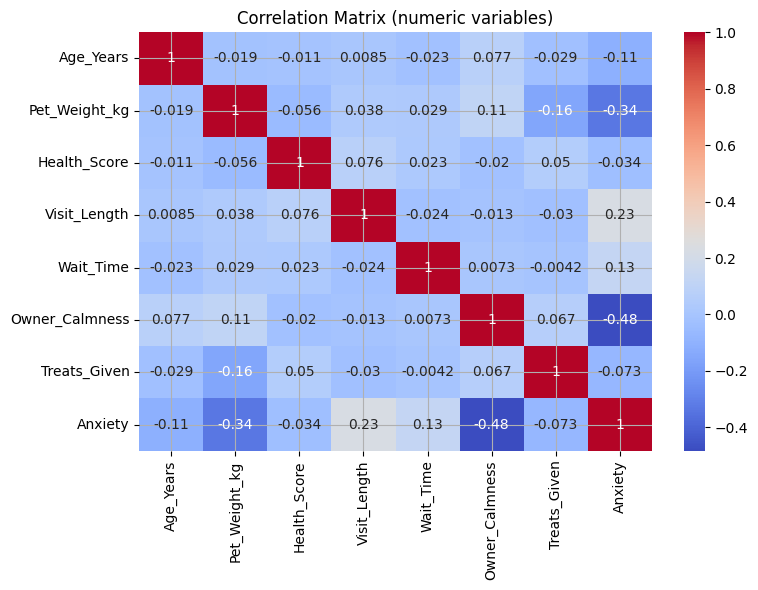

In [4]:

import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings

#from google.colab import drive
#if True:
#  drive.mount('/content/drive')



# Install gdown if you don't have it (pre-installed in Google Colab)
first = False
if first:
  !pip install --upgrade gdown
#  first = False

import gdown
import pandas as pd

file_id = '1Z6KAI-3rd7zmwcuOVu_lC9WXiMgYI9zM'

output = 'pets_vet_anxiety_dataset-1.csv'
gdown.download(id=file_id, output=output, quiet=False)
df = pd.read_csv(output)

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7.5,4.5)
plt.rcParams["axes.grid"] = True

display(df.head())
print(df.info())
display(df.select_dtypes(include=[np.number]).describe().round(2))
display(df.select_dtypes(include=['object']).nunique())

num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix (numeric variables)")
plt.tight_layout()
plt.show()


## Task 2 — Linear Regression

- Split data into train/test (80/20) to predict `Anxiety` from sensible predictors  
- Fit a `LinearRegression` model in a `Pipeline` with `StandardScaler`  
- Report **R²** on train and test; list the top 5 absolute coefficients (by magnitude)  


Linear Regression —  R² (train): 0.477
Linear Regression —  R² (test):  0.415


,feature,coef,abs_coef
8,Species_Cat,1.113136,1.113136
5,Owner_Calmness,-1.014155,1.014155
10,Species_Rabbit,0.458095,0.458095
9,Species_Dog,0.430779,0.430779
3,Visit_Length,0.410382,0.410382
4,Wait_Time,0.289330,0.289330
7,Invasive_Treatment,0.277842,0.277842
6,Treats_Given,-0.222979,0.222979
2,Health_Score,-0.176237,0.176237
0,Age_Years,-0.165207,0.165207


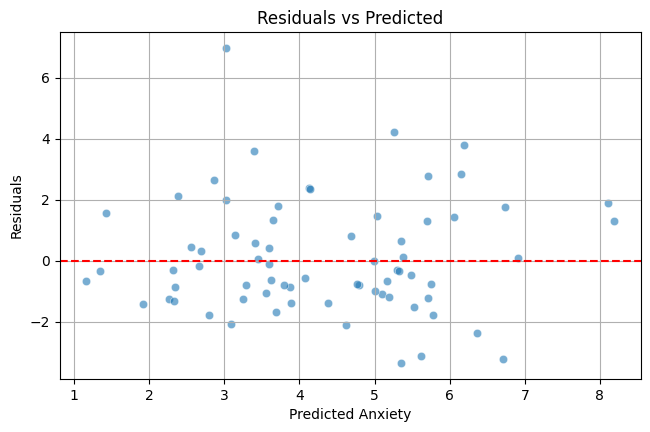

In [ ]:

import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

target = "Anxiety"

# Let's turn Species into a numerical value to see it in the table
df_model = pd.get_dummies(df.copy(), columns=["Species"], drop_first=True)
features = [c for c in df_model.columns if c not in ["Pet_ID","Visit_ID","Pet_Name", target]]
X = df_model[features].astype(float)
y = df_model[target].astype(float)

# Split dataset into test and training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# This pipeline will run the items contained in order
# Standard Scaler applies a normalization
pipe_lr = Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())])
pipe_lr.fit(X_train, y_train)
pred_tr = pipe_lr.predict(X_train)
pred_te = pipe_lr.predict(X_test)

r2_tr = r2_score(y_train, pred_tr)
r2_te = r2_score(y_test, pred_te)

print(f"Linear Regression —  R² (train): {r2_tr:.3f}")
print(f"Linear Regression —  R² (test):  {r2_te:.3f}")

# You can print the coefficients (w) to see how much each coefficient matters to the fit
coefs = pipe_lr.named_steps['lr'].coef_
coef_df = pd.DataFrame({'feature': X_train.columns, 'coef': coefs, 'abs_coef': np.abs(coefs)}).sort_values('abs_coef', ascending=False)
display(coef_df.head(10))

#Got help from AI to figure how to adjust the plot
residuals = y_test - pred_te
sns.scatterplot(x=pred_te, y=residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Anxiety")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()


## Q1 - Is the linear regression model from task 2 a good fit? (1+3 ⭕️s)

⭕️



Extra Credit - How do you know if it is a good fit? List 2 reasons for why or why not.

⭕️⭕️⭕️

It is a decent fit as the R^2 values as the R^2 squares are well above 0, meaning they are better predictors than the mean. However, it is far from great as it would need a much higher R^2 value to be reliable. The residuals are randomly scattered across 0 which is usually indicative of a good fit



## Task 3 — Fit a regression model to predict Cat anxiety





First, let's inspect the dataset to decide what variables to use:
- Visualize the correlation matrix for Cats only (make it civilized and with values printed on each item)

- Visualize the pairplot for cats only. Pick a reasonable variable for hue

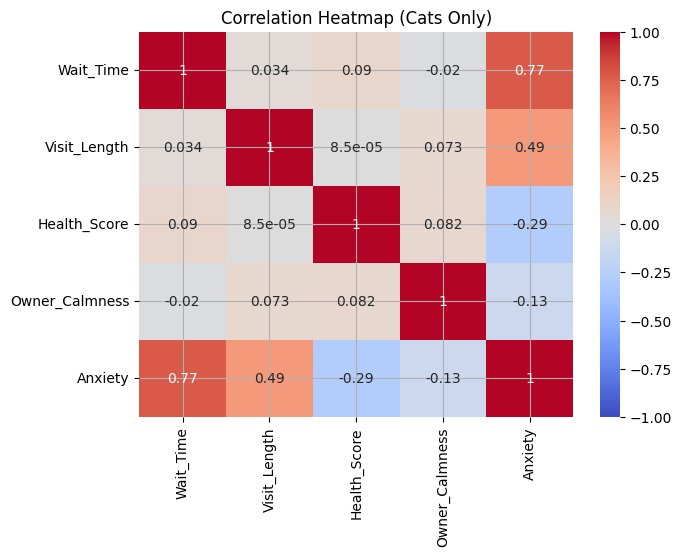

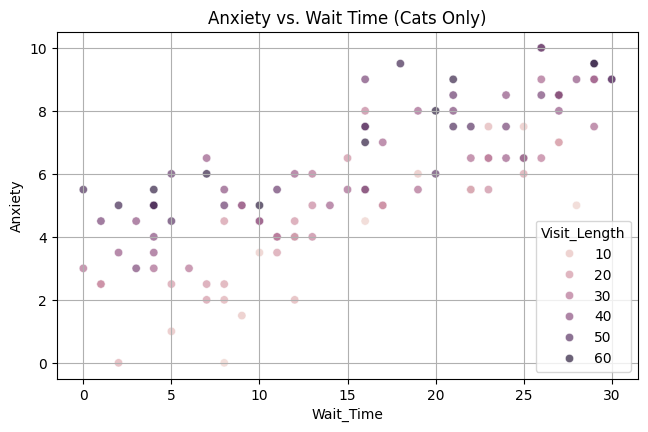

In [ ]:
num_cols = ["Wait_Time", "Visit_Length", "Health_Score", "Owner_Calmness", "Anxiety"]
cats = df.query("Species == 'Cat'")
corr = cats[num_cols].corr()

plt.figure(figsize=(7,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Cats Only)")
plt.show()

sns.scatterplot(data=cats, x="Wait_Time", y="Anxiety", hue="Visit_Length", alpha=0.7)
plt.title("Anxiety vs. Wait Time (Cats Only)")
plt.show()

## Task 3 Questions (4 ⭕️s)



### Visualizations (2 plots above)

⭕️


### Q2 - What did you learn from each of the visualizations above?

⭕️



 From the heatmap, the two highest factors for a cat's anxiety are both time related, being wait time and visit length. The other variables are weakly negatively correlated. Perhaps this indicates that cats get stressed from being in a strange enviroment rather than anything specific about the care or thier condition.

From the scatterplot, we can see that the correlation between wait time and anxiety looks roughly linear. Visit length does not give me as much as I thought, being obviously correlated with anxiety but not revealing much with wait time, perhaps because there is too little data to see any clusters or other features.




### Q3 - What variable(s) will you be using for your fit?

⭕️

I will be using wait_time, visit_length, and health_score to predict anxiety

### Q4 - What model will you be fitting? (Linear/Polynomial)

⭕️

Linear

## Fit your model for task 3 (5 ⭕️s)
- Remember to split 80/20 and scale the values



In [1]:

import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

target = "Anxiety"

# Let's turn Species into a numerical value to see it in the table
cats_model = pd.get_dummies(cats.copy(), columns=["Species"], drop_first=True)
feature = ["Wait_Time", "Visit_Length", "Health_Score"]
X = cats_model[feature].astype(float)
y = cats_model[target].astype(float)

# Split dataset into test and training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# This pipeline will run the items contained in order
# Standard Scaler applies a normalization
pipe_lr = Pipeline([("scaler", StandardScaler()), ("lr", LinearRegression())])
pipe_lr.fit(X_train, y_train)
pred_tr = pipe_lr.predict(X_train)
pred_te = pipe_lr.predict(X_test)

r2_tr = r2_score(y_train, pred_tr)
r2_te = r2_score(y_test, pred_te)

print(f"Linear Regression —  R² (train): {r2_tr:.3f}")
print(f"Linear Regression —  R² (test):  {r2_te:.3f}")

residuals = y_test - pred_te
sns.scatterplot(x=pred_te, y=residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Anxiety")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()

NameError: name 'cats' is not defined

### Produce metrics to evaluate your model

- Visualize the residuals, plot $y$ vs $\hat y$, and print the value of $R^2$ for your fit.

⭕️⭕️⭕️

**Your model must have $R^2$ > 0.8 to get any points for this section**

- Print the coefficients ($w_i$) for each feature used (include engineered if your model used any)  

⭕️⭕️

In [ ]:
coefs = pipe_lr.named_steps['lr'].coef_
coef_df = pd.DataFrame({'feature': X_train.columns, 'coef': coefs, 'abs_coef': np.abs(coefs)}).sort_values('abs_coef', ascending=False)
display(coef_df.head(10))

,feature,coef,abs_coef
0,Wait_Time,1.777159,1.777159
1,Visit_Length,1.036551,1.036551
2,Health_Score,-0.798931,0.798931


## Task 4 — Fit a regression model to predict Dog anxiety



First, let's inspect the dataset to decide what variables to use:
- Visualize the correlation matrix for Dogs only (make it civilized and with values printed on each item)

- Visualize the pairplot for dogs only. Pick a reasonable variable for hue


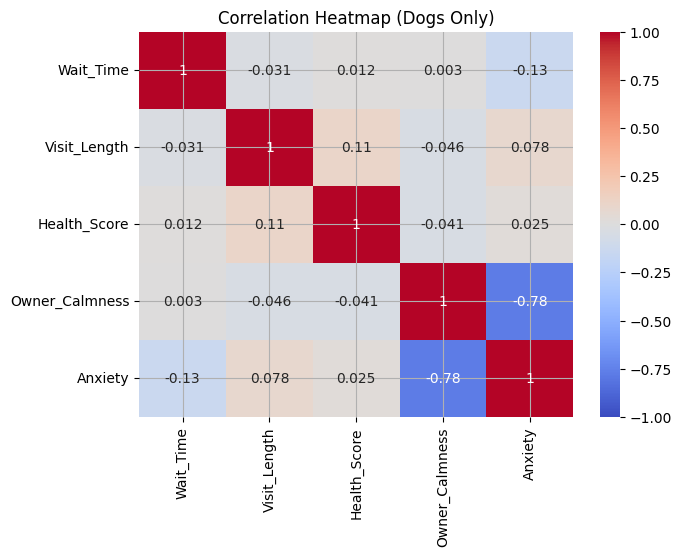

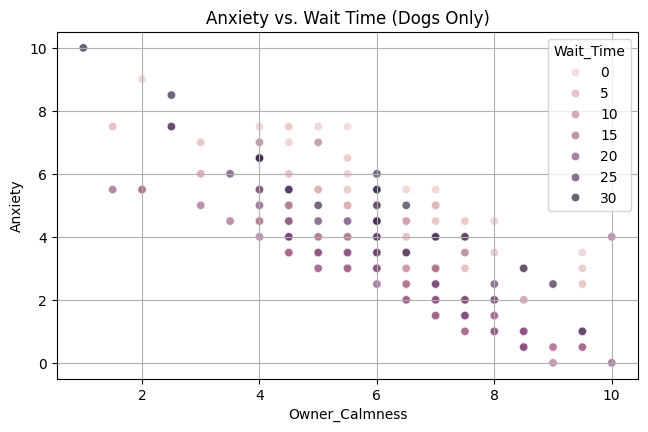

In [6]:
num_cols = ["Wait_Time", "Visit_Length", "Health_Score", "Owner_Calmness", "Anxiety"]
dogs = df.query("Species == 'Dog'")
dcorr = dogs[num_cols].corr()

plt.figure(figsize=(7,5))
sns.heatmap(dcorr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Dogs Only)")
plt.show()

sns.scatterplot(data=dogs, x="Owner_Calmness", y="Anxiety", hue="Wait_Time", alpha=0.7)
plt.title("Anxiety vs. Wait Time (Dogs Only)")
plt.show()

## Task 4 Questions (4 ⭕️s)



### Visualizations (2 plots above)

⭕️


### Q5 - What did you learn from each of the visualizations above?

⭕️



Dogs are heavily affected by owner calmness with a negative correlation of -.78 with no other strong correlations. The scatter plot really just confirms this.






### Q6 - What variable(s) will you be using for your fit?

⭕️

Owner Calmness and Wait time

### Q7 - What model will you be fitting? (Linear/Polynomial)

⭕️

In [ ]:
Polynomial

Owner Calmness and Wait time




Linear Regression —  R² (train): 0.939
Linear Regression —  R² (test):  0.969


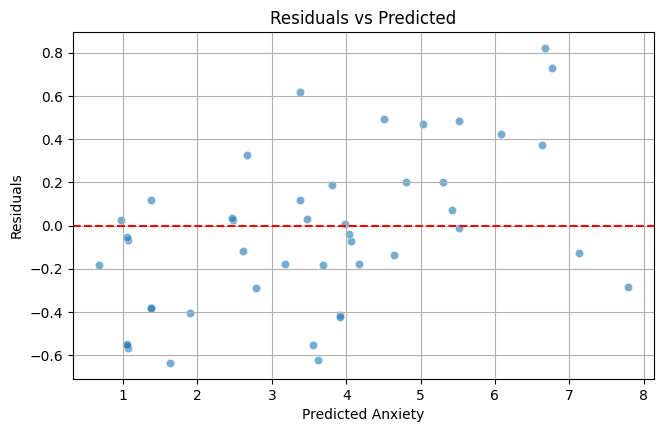

In [7]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

target = "Anxiety"

dogs_model = pd.get_dummies(dogs.copy(), columns=["Species"], drop_first=True)
features = ["Owner_Calmness", "Wait_Time"]
X = dogs_model[features].astype(float)
y = dogs_model[target].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# got code adjusted with AI
pipe_lr = Pipeline(
    [
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lr", LinearRegression()),
    ]
)


pipe_lr.fit(X_train, y_train)
pred_tr = pipe_lr.predict(X_train)
pred_te = pipe_lr.predict(X_test)

r2_tr = r2_score(y_train, pred_tr)
r2_te = r2_score(y_test, pred_te)

print(f"Linear Regression —  R² (train): {r2_tr:.3f}")
print(f"Linear Regression —  R² (test):  {r2_te:.3f}")

residuals = y_test - pred_te
sns.scatterplot(x=pred_te, y=residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Anxiety")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.show()

## Fit your model for task 4 (5 ⭕️s)
- Remember to split 80/20 and scale the values

### Produce metrics to evaluate your model

- Visualize the residuals, plot $y$ vs $\hat y$, and print the value of $R^2$ for your fit.

⭕️⭕️⭕️

**Your model must have $R^2$ > 0.8 to get any points for this section**

- Print the coefficients ($w_i$) for each feature used (include engineered if your model used any)  

⭕️⭕️

In [ ]:
coefs = pipe_lr.named_steps['lr'].coef_
coef_df = pd.DataFrame({'feature': X_train.columns, 'coef': coefs, 'abs_coef': np.abs(coefs)}).sort_values('abs_coef', ascending=False)
display(coef_df.head(10))

## Recommendations (6 ⭕️s)



### Q8 - What would you recommend for Cat owners to reduce their pet's anxiety at the vet?
Quantify your recommendation (Example: how much do you expect it to improve? Any **correct** quantitative metric to motivate your recommendation is OK)

⭕️⭕️




The owners should try to limit the amount of time spent at the vet. One way would to schedule appointments ahead of time so that wait time is reduced as the length of the checkup is not in the hands of the owner


### Q9 - What would you recommend for Dog owners to reduce their pet's anxiety at the vet?

Quantify your recommendation (Example: how much do you expect it to improve? Any **correct** quantitative metric to motivate your recommendation is OK)

⭕️⭕️


The owner should remain as calm as they can as this is the highest factor affecting their dog's anxiety




### Q10 - What can the vet do to reduce the anxiety of the pets that they serve?

Quantify your recommendation (Example: how much do you expect it to improve? Any **correct** quantitative metric to motivate your recommendation is OK)

⭕️⭕️

The vet can try to have smaller wait times and visit lengths, which are the factors most in control that affect stress, and to recommend that owners remain calm
